# Hasil Analisis Tugas 3: Distribusi Error dan Feature Importance

Notebook ini hanya membaca keluaran `src/07_analysis.ipynb` (folder `results_c/analysis/`) lalu membuat grafik.
Jalankan `src/07_analysis.ipynb` terlebih dahulu. Tidak ada model yang dilatih di sini.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

ROOT = Path("..") if Path("../results_c").exists() else Path(".")
ANALYSIS = ROOT / "results_c" / "analysis"
koma = FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ","))

ringkas = json.loads((ANALYSIS / "error_ringkasan.json").read_text())
err = pd.read_csv(ANALYSIS / "error_per_tanggal.csv", parse_dates=["date"])
kel = pd.read_csv(ANALYSIS / "error_per_kelompok.csv")
imp = pd.read_csv(ANALYSIS / "permutation_importance_fitur.csv", index_col=0).iloc[:, 0]
imp_kel = pd.read_csv(ANALYSIS / "permutation_importance_kelompok.csv")
print({k: ringkas[k] for k in ["tabel", "DA_C", "DA_C_ci95", "DA_A", "DA_A_ci95", "dDA_ci95", "mcnemar_p_dua_sisi"]})

{'tabel': {'keduanya benar': 57, 'hanya C benar': 47, 'hanya A benar': 32, 'keduanya salah': 42}, 'DA_C': 0.5842696629213483, 'DA_C_ci95': [0.506, 0.652], 'DA_A': 0.5, 'DA_A_ci95': [0.421, 0.573], 'dDA_ci95': [-0.006, 0.18], 'mcnemar_p_dua_sisi': 0.11466035574580133}


## 1. Tabel kontingensi Model A vs Model C (test)

In [2]:
kont = pd.crosstab(err["pred_A"] == err["target"], err["pred_C"] == err["target"])
kont.index = ["A salah", "A benar"]; kont.columns = ["C salah", "C benar"]
kont

,C salah,C benar
A salah,42,47
A benar,32,57


## 2. DA per bulan, per jumlah artikel, dan per besar gerakan kurs

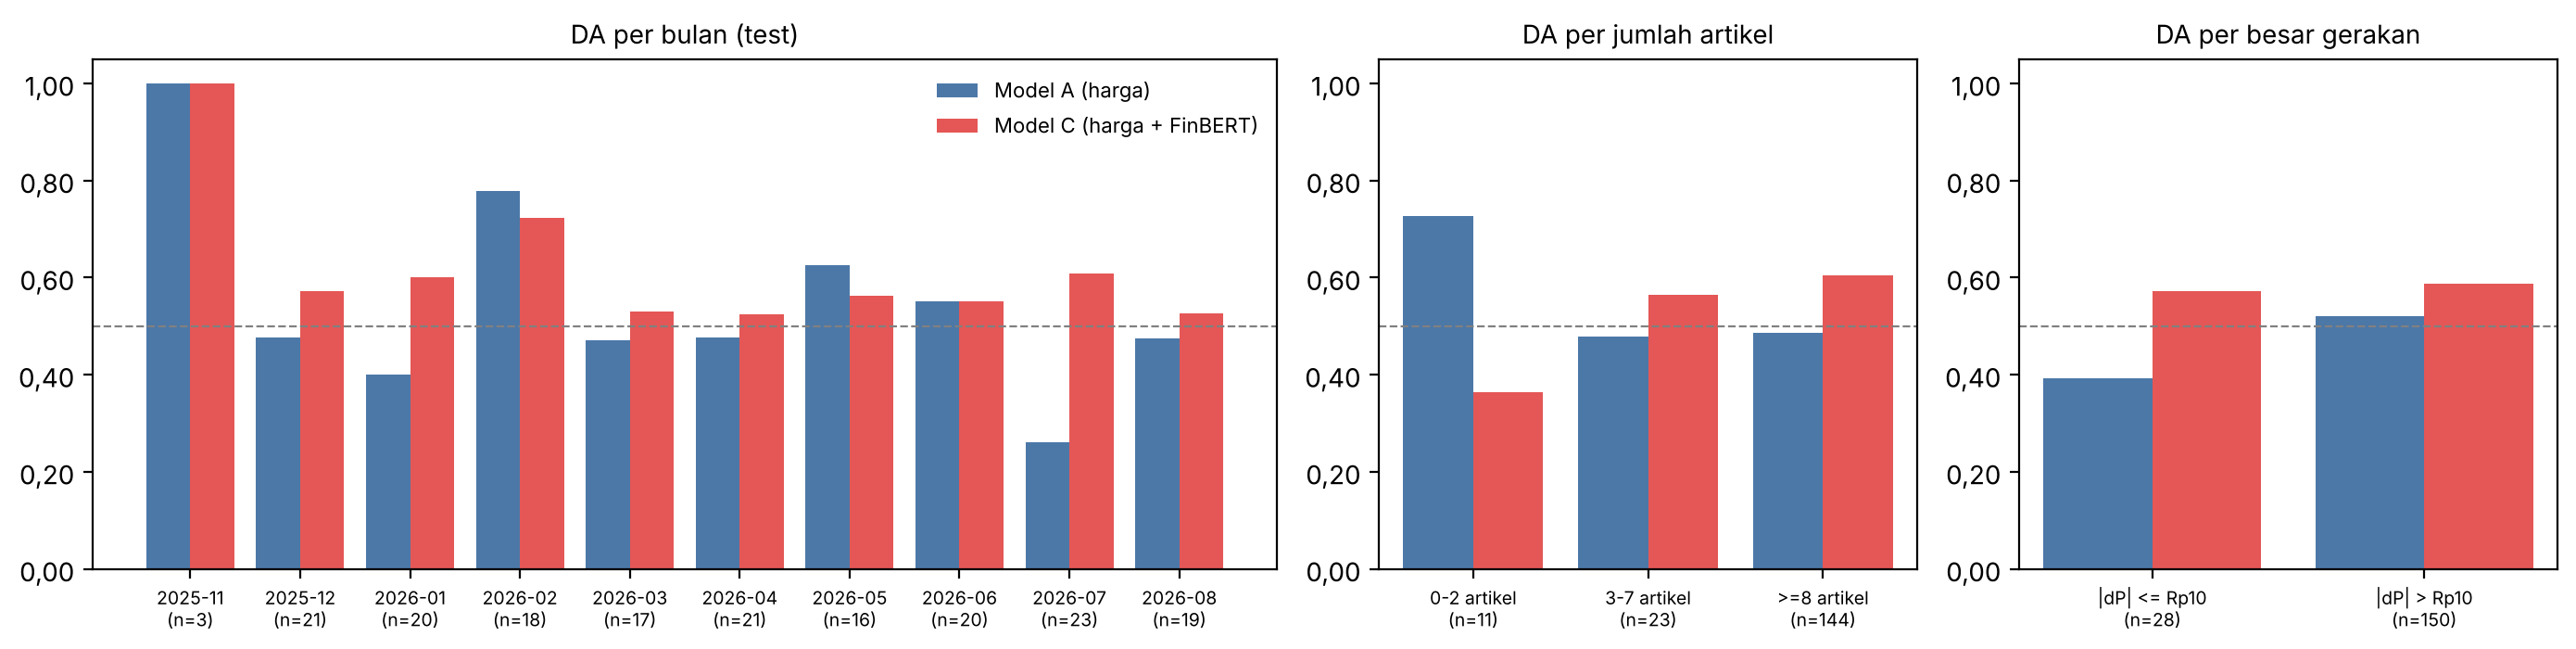

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[2.2, 1, 1]))
for a, jenis, judul in zip(ax, ["bulan", "kelompok_artikel", "kelompok_gerak"],
                           ["DA per bulan (test)", "DA per jumlah artikel", "DA per besar gerakan"]):
    k = kel[kel["jenis"] == jenis].reset_index(drop=True)
    x = np.arange(len(k))
    a.bar(x - 0.2, k["DA_A"], 0.4, label="Model A (harga)", color="#4C78A8")
    a.bar(x + 0.2, k["DA_C"], 0.4, label="Model C (harga + FinBERT)", color="#E45756")
    a.axhline(0.5, color="gray", lw=0.8, ls="--")
    a.set_xticks(x, [f"{g}\n(n={h})" for g, h in zip(k["kelompok"], k["hari"])], fontsize=7, rotation=0)
    a.set_ylim(0, 1.05); a.yaxis.set_major_formatter(koma); a.set_title(judul, fontsize=10)
ax[0].legend(fontsize=8, frameon=False, loc="upper right")
plt.tight_layout(); plt.savefig(ANALYSIS / "da_per_kelompok.png", dpi=150); plt.show()

## 3. Peluang naik per tanggal: kapan C membantu dan kapan menambah noise

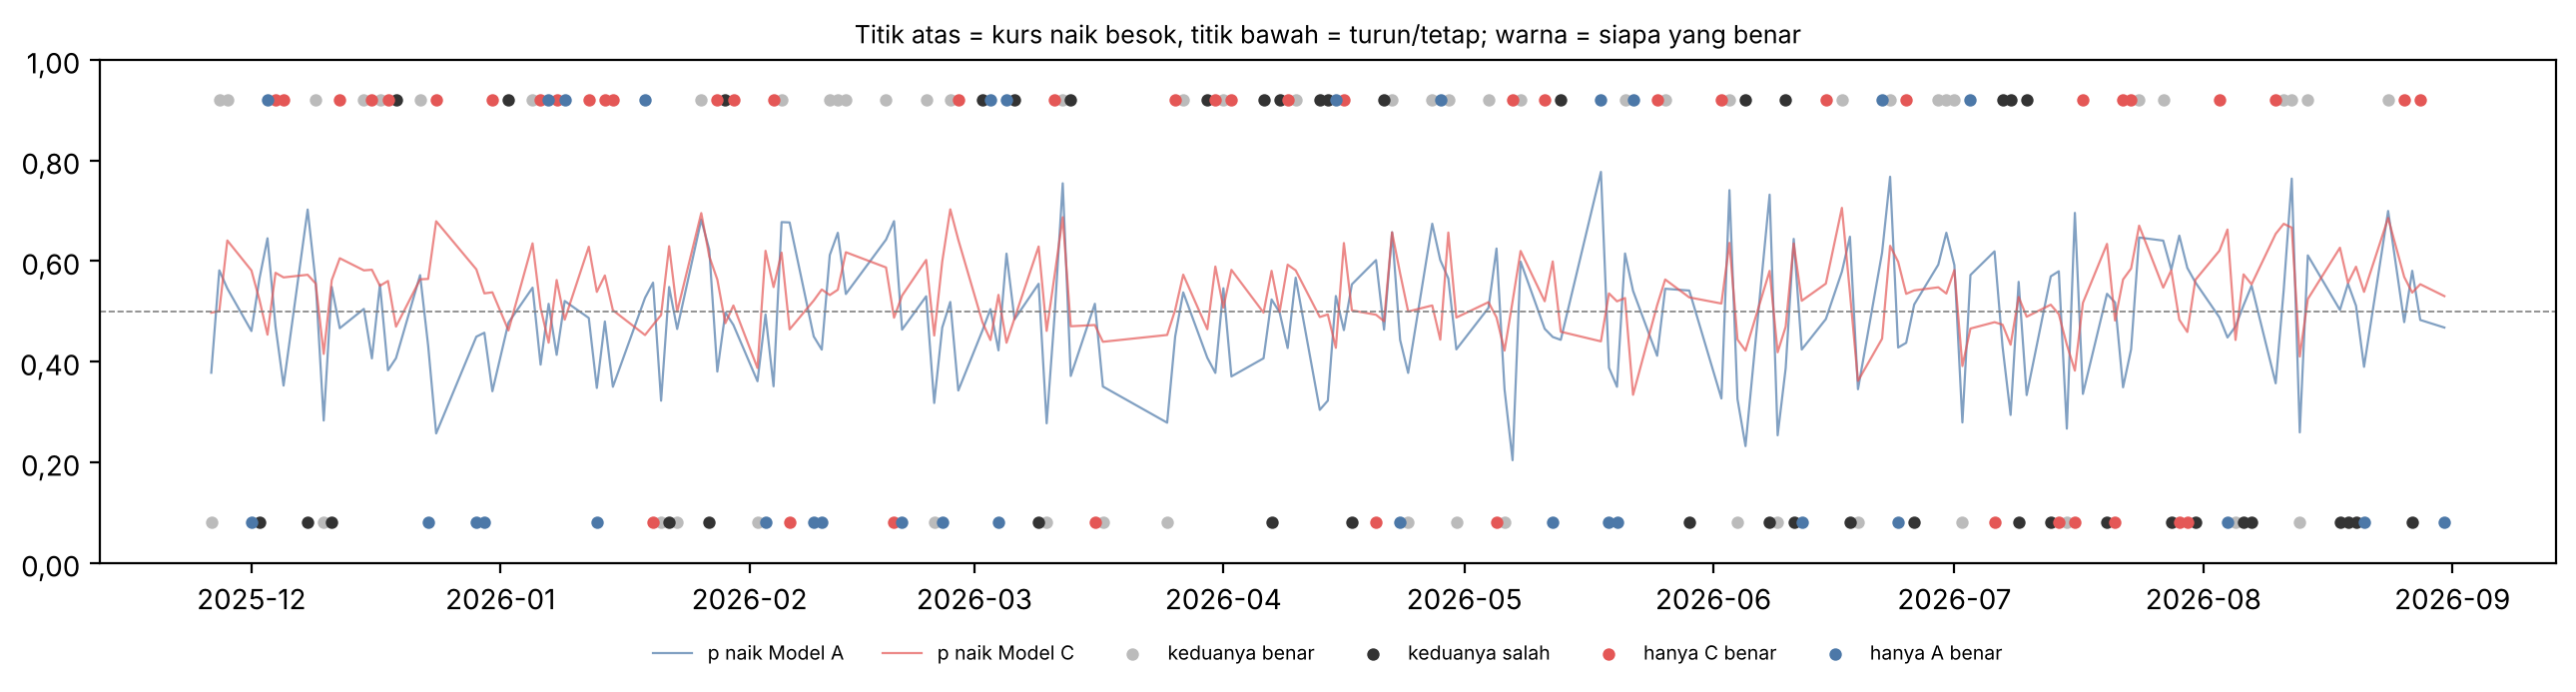

In [4]:
warna = {"keduanya benar": "#BBBBBB", "keduanya salah": "#333333", "hanya C benar": "#E45756", "hanya A benar": "#4C78A8"}
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(err["date"], err["p_A"], color="#4C78A8", lw=0.8, alpha=0.7, label="p naik Model A")
ax.plot(err["date"], err["p_C"], color="#E45756", lw=0.8, alpha=0.7, label="p naik Model C")
for kat, c in warna.items():
    m = err["kategori"] == kat
    ax.scatter(err.loc[m, "date"], np.where(err.loc[m, "target"] == 1, 0.92, 0.08), s=12, color=c, label=kat)
ax.axhline(0.5, color="gray", lw=0.6, ls="--")
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(koma)
ax.set_title("Titik atas = kurs naik besok, titik bawah = turun/tetap; warna = siapa yang benar", fontsize=9)
ax.legend(fontsize=7, ncol=6, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.savefig(ANALYSIS / "prob_per_tanggal.png", dpi=150); plt.show()

In [5]:
contoh = pd.read_csv(ANALYSIS / "error_contoh_tanggal.csv")
pd.set_option("display.max_colwidth", 110)
contoh[["kategori", "date", "dP_rupiah", "p_A", "p_C", "jumlah_berita", "event_dominan", "judul"]]

,kategori,date,dP_rupiah,p_A,p_C,jumlah_berita,event_dominan,judul
0,hanya C benar,2026-05-11,99,0.47,0.52,12,war/conflict,"Putin says he thinks Russia-Ukraine war is coming to an end | U.S., Iran no closer to ending war as Qatari..."
1,hanya C benar,2026-07-16,-97,0.70,0.38,8,economic data,Dallas Fed President Logan calls for 'modestly' higher interest rates | Banking Committee's Sen. Rounds li...
2,hanya C benar,2026-02-27,69,0.34,0.64,7,monetary policy,Anthropic faces lose-lose scenario in Pentagon conflict as deadline for policy change looms | 10-year yiel...
3,hanya C benar,2026-06-02,68,0.33,0.52,28,monetary policy,Oil exports through the Strait of Hormuz might not return to levels seen before the Iran war | European de...
4,hanya C benar,2026-01-28,63,0.38,0.56,15,monetary policy,Gold jumps to fresh highs as Asia stock markets mostly rise after U.S. Fed holds rates | Where to still fi...
5,hanya C benar,2026-07-23,58,0.42,0.59,25,economic data,"U.S. to see higher generic drug prices thanks to tariffs, CEO of leading India pharma firm warns | 10-year..."
6,hanya A benar,2026-06-12,-202,0.42,0.52,2,economic data,"Treasury yields move higher as traders monitor potential U.S.-Iran peace deal | For Warsh as Fed chair, si..."
7,hanya A benar,2026-08-04,-100,0.45,0.66,16,monetary policy,"Iran, Oman say Strait of Hormuz talks in final stages, as Trump again teases a deal being close | Here's T..."
8,hanya A benar,2026-04-28,79,0.60,0.44,11,economic data,"Dollar firms, yen steady as markets weigh Iran war, split BOJ decision | Inflation could get in the way of..."
9,hanya A benar,2026-02-20,-67,0.46,0.53,16,monetary policy,Supreme Court Trump tariff decision impact: What to expect as fight for billions in refunds begins | Fourt...


## 4. Permutation importance

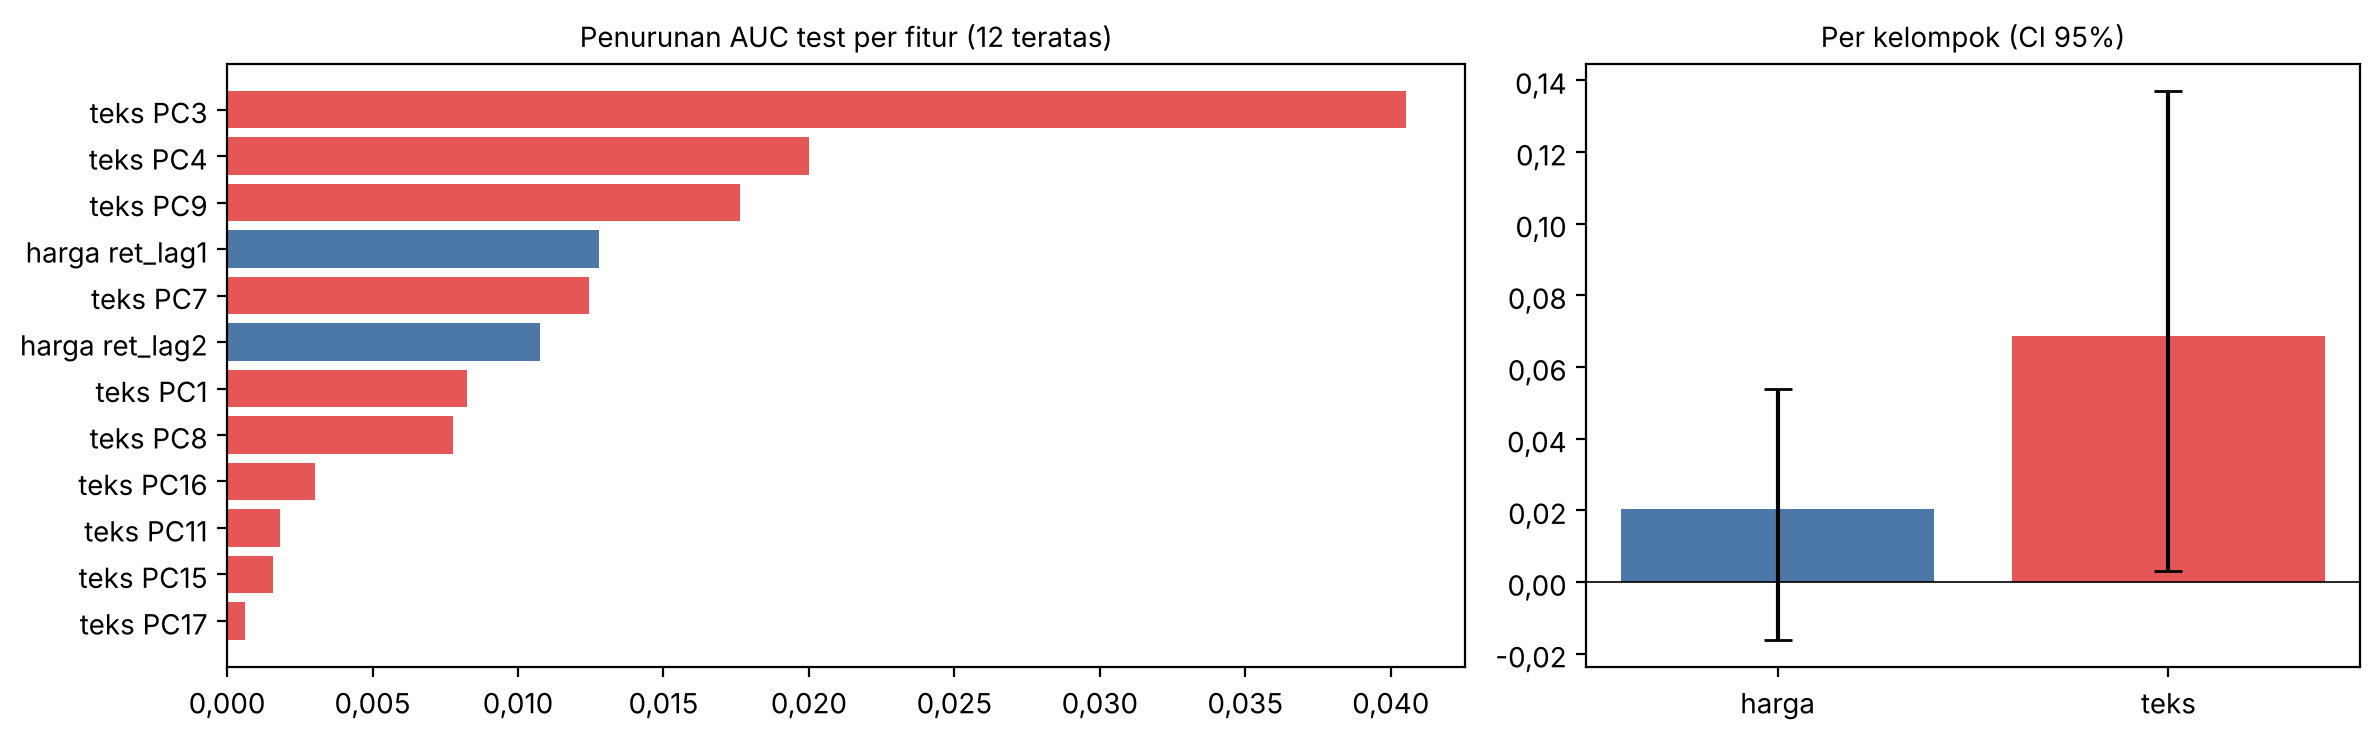

In [6]:
top = imp.head(12)[::-1]
label = [("teks PC" + i.split("_")[-1]) if i.startswith("c2_art_cls_") and i != "c2_art_cls_has"
         else ("teks has_news" if i == "c2_art_cls_has" else "harga " + i) for i in top.index]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax[0].barh(label, top.values, color=["#E45756" if l.startswith("teks") else "#4C78A8" for l in label])
ax[0].axvline(0, color="k", lw=0.6); ax[0].set_title("Penurunan AUC test per fitur (12 teratas)", fontsize=10)
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.3f}".replace(".", ",")))
yerr = [imp_kel["turun_auc"] - imp_kel["ci95_bawah"], imp_kel["ci95_atas"] - imp_kel["turun_auc"]]
ax[1].bar(imp_kel["kelompok"], imp_kel["turun_auc"], yerr=yerr, capsize=5, color=["#4C78A8", "#E45756"])
ax[1].axhline(0, color="k", lw=0.6); ax[1].set_title("Per kelompok (CI 95%)", fontsize=10)
ax[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",")))
plt.tight_layout(); plt.savefig(ANALYSIS / "permutation_importance.png", dpi=150); plt.show()

In [7]:
pd.read_csv(ANALYSIS / "tafsir_komponen_pca.csv")

,komponen,judul_tertinggi,judul_terendah,rho_event_terkuat
0,c2_art_cls_3,Oil extends losses on prospect of higher OPEC+ supply || Oil prices climb on hurricane impact ahead of U.S...,How 5 companies are using pricing power to protect profits during high inflation || There are key differen...,"financial markets +0.18, oil/energy +0.15, trade/tariffs -0.11"
1,c2_art_cls_4,"China has spent at least $230 billion to build its EV industry, new study finds || Linde's ability to mana...","From mortgages to auto loans, experts weigh in on when — or if — to refinance as interest rates fall || Wa...","monetary policy -0.19, financial markets +0.15, war/conflict +0.09"
2,c2_art_cls_9,Here are the top-performing technology stocks of 2021 || Competing bills could ban lawmakers from trading ...,"In the face of trade tensions, China says it will focus on its own economy || Huawei's smartphone spinoff ...","economic data -0.21, oil/energy +0.16, war/conflict -0.16"


## 5. Catatan interpretasi

- Bukti bahwa teks membantu masih lemah: selisih DA C terhadap A belum signifikan, dan DA C tidak melampaui proporsi kelas mayoritas test.
- Grafik per jumlah artikel menunjukkan hari dengan 0-2 artikel sebagai sumber kesalahan C: rata-rata vektor harian dari satu atau dua berita mudah menjadi noise.
- Komponen teks yang paling berpengaruh lebih terkait dengan berita minyak, pasar, dan kebijakan moneter, tetapi korelasinya kecil sehingga perlu ditafsirkan hati-hati.